In [8]:
%pylab inline
import os
import catutil
import astropy.io.fits as pyfits
import pltutil

Populating the interactive namespace from numpy and matplotlib


In [2]:
datDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_others/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'
datDir2='wrkDir/s19/s19-pre/psf_test_from_wentao/results/'
datDir3='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/'

104246
561643
538952
294382
509085
202368
2210676.0


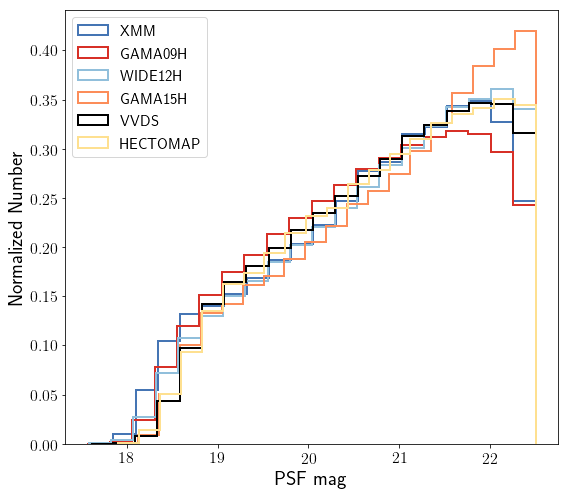

In [17]:
plt.close()
fig=plt.figure(figsize=(8,7))
ax=fig.add_subplot(1,1,1)
sumAll=0.
for fieldname in catutil.field_names:
    fname='%s_star.fits'%fieldname
    fname=os.path.join(datDir,fname)
    data=pyfits.getdata(fname)
    data=data[data['i_calib_psf_used']]
    mag=data['i_psfflux_mag']
    n1=len(data)
    sumAll+=n1
    print(n1)
    ax.hist(mag,bins=20,color=pltutil.plot_colors[fieldname],histtype='step',density=True,\
            linewidth=2.,label=fieldname)
    ax.set_xlabel(r'PSF mag ', fontsize=20)
    ax.set_ylabel('Normalized Number',fontsize=20)
    
print(sumAll)
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(pltDir,'psf_mag_dis2.eps'))

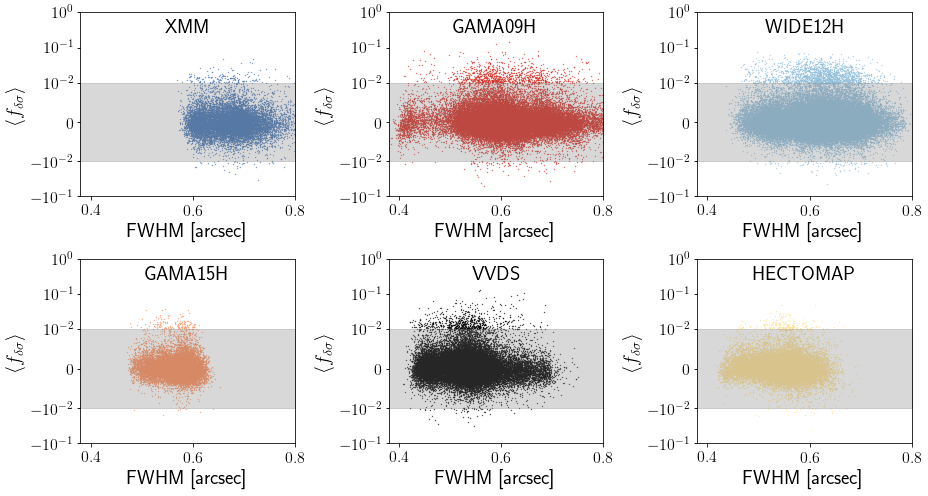

In [8]:
plt.close()
bandx   = [0.38,0.8]
bandyp  = [0.01,0.01]
bandyn  = [-0.01,-0.01]
fig = plt.figure(figsize=(13,7))
fig.set_rasterized(True) 
ip=0
for fieldname in catutil.field_names:
    ip+=1
    fnt2,sgt2 = np.loadtxt(datDir2+'%s_healpy_cuts.dat'%fieldname,unpack=True)
    idx     = np.abs(fnt2)<=10.02
    fn2     = fnt2[idx]
    sg2     = sgt2[idx]

    ax=fig.add_subplot(2,3,ip)
    ax.scatter(sg2,fn2,s=0.1,color=pltutil.plot_colors[fieldname])
    ax.fill_between(bandx,bandyp,bandyn,alpha=0.3,color='grey')
    ax.set_xlim(0.38,0.8)
    ax.set_ylim(-0.1,1)
    ax.set_yscale('symlog',linthreshy=0.01)
    ax.set_title(fieldname,fontsize=20,y=1.0, pad=-20)
    ax.set_xlabel(r'FWHM [arcsec]',fontsize=20)
    ax.set_ylabel(r'$\langle f_{\delta\sigma} \rangle$',fontsize=20)
    ax.set_rasterized(True)
plt.tight_layout()
fig.savefig(os.path.join(pltDir,'psf_test_healpix.eps'),rasterized=True,dpi=100)

115653
615436
580914
316525
547314
216165
2392007.0


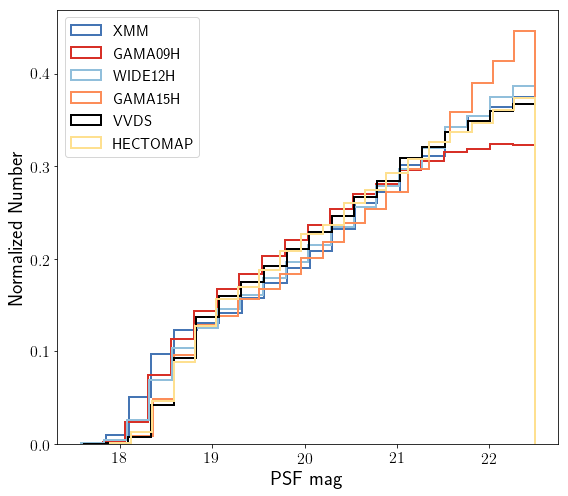

In [16]:
#All
plt.close()
fig=plt.figure(figsize=(8,7))
ax=fig.add_subplot(1,1,1)
sumAll=0.
for fieldname in catutil.field_names:
    fname='%s_star.fits'%fieldname
    fname=os.path.join(datDir,fname)
    data=pyfits.getdata(fname)
    n1=len(data)
    sumAll+=n1
    print(n1)
    mag=data['i_psfflux_mag']
    ax.hist(mag,bins=20,color=pltutil.plot_colors[fieldname],histtype='step',density=True,\
            linewidth=2.,label=fieldname)
    ax.set_xlabel(r'PSF mag ', fontsize=20)
    ax.set_ylabel('Normalized Number',fontsize=20)
    
print(sumAll)
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
#fig.savefig(os.path.join(pltDir,'psf_mag_dis2.eps'))

11407
53793
41962
22143
38229
13797
181331.0


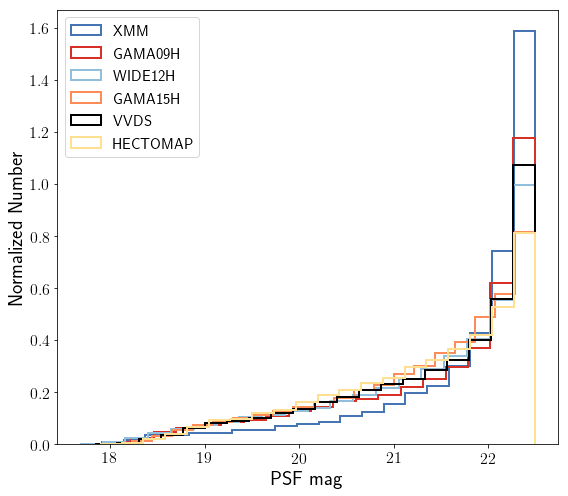

In [16]:
# non-PSF
plt.close()
fig=plt.figure(figsize=(8,7))
ax=fig.add_subplot(1,1,1)
sumAll=0.
for fieldname in catutil.field_names:
    fname='%s_star.fits'%fieldname
    fname=os.path.join(datDir,fname)
    data=pyfits.getdata(fname)
    data=data[~data['i_calib_psf_used']]
    n1=len(data)
    sumAll+=n1
    print(n1)
    mag=data['i_psfflux_mag']
    ax.hist(mag,bins=20,color=pltutil.plot_colors[fieldname],\
            histtype='step',density=True,\
            linewidth=2.,label=fieldname)
    ax.set_xlabel(r'PSF mag ', fontsize=20)
    ax.set_ylabel('Normalized Number',fontsize=20)
    
print(sumAll)
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
#fig.savefig(os.path.join(pltDir,'psf_mag_dis2.eps'))

2446758
2446758.0
186529


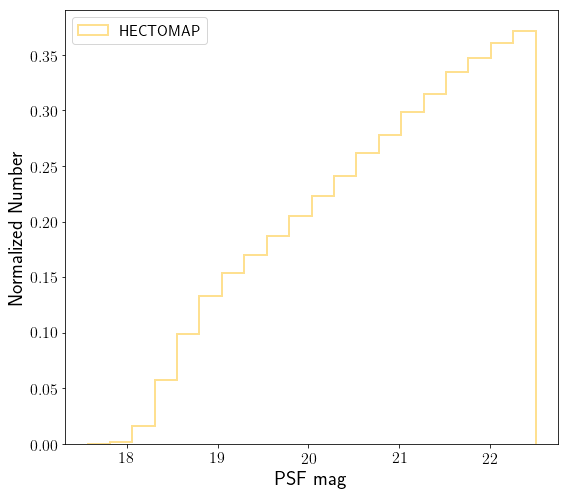

In [17]:
plt.close()
fig=plt.figure(figsize=(8,7))
ax=fig.add_subplot(1,1,1)
sumAll=0.
fname='all_fields_sm-S19A-g15_star.fits'
fname=os.path.join(datDir3,fname)
data=pyfits.getdata(fname)
mag=data['i_psfflux_mag']
n1=len(data)
sumAll+=n1
print(n1)
ax.hist(mag,bins=20,color=pltutil.plot_colors[fieldname],histtype='step',density=True,\
        linewidth=2.,label=fieldname)
ax.set_xlabel(r'PSF mag ', fontsize=20)
ax.set_ylabel('Normalized Number',fontsize=20)
    
print(sumAll)
print(np.sum(~data['i_calib_psf_used']))
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
#fig.savefig(os.path.join(pltDir,'psf_mag_dis2.eps'))

In [30]:
np.sum(data['i_calib_psf_used']==False)

186529

['object_id', 'parent_id', 'i_ra', 'i_dec', 'i_psfflux_mag', 'i_psfflux_magerr', 'i_psfflux_flux', 'i_psfflux_fluxerr', 'i_psfflux_flag', 'i_sdssshape_shape11', 'i_sdssshape_shape22', 'i_sdssshape_shape12', 'i_sdssshape_shape11err', 'i_sdssshape_shape22err', 'i_sdssshape_shape12err', 'i_sdssshape_psf_shape11', 'i_sdssshape_psf_shape22', 'i_sdssshape_psf_shape12', 'tract', 'i_calib_psf_used', 'merge_peak_g', 'merge_peak_r', 'merge_peak_r2', 'merge_peak_i', 'merge_peak_i2', 'merge_peak_z', 'merge_peak_y', 'i_inputcount_value', 'i_deblend_hasstrayflux', 'i_blendedness_abs', 'i_sdsscentroid_flag', 'i_deblend_toomanypeaks', 'i_deblend_parenttoobig', 'i_pixelflags_interpolated', 'i_pixelflags_saturated', 'i_pixelflags_cr', 'i_pixelflags_suspect', 'i_pixelflags_inexact_psfcenter', 'i_pixelflags_inexact_psf', 'i_mask_s18a_bright_objectcenter', 'i_mask_brightstar_any', 'i_mask_brightstar_halo', 'i_mask_brightstar_dip', 'i_mask_brightstar_ghost', 'i_mask_brightstar_blooming', 'i_mask_brightstar_

(array([1645854.,  924860., 1159208.,  937191.,  976761., 1019509.,
         977065.,  787787.,  525198.,  290783.,  141142.,   66801.,
          34084.,   20129.,   13562.,   10248.,    8478.,    7559.,
           6839.,   11902.]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
        13., 14., 15., 16., 17., 18., 19., 20.]),
 <a list of 20 Patch objects>)

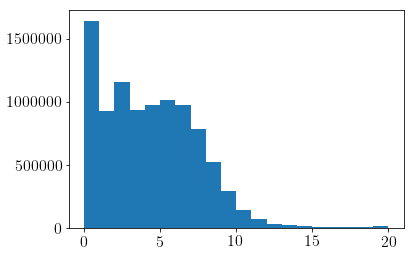

In [18]:
fname='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/fgcmStandardStars-06.fits'
eli=pyfits.getdata(fname)
print(data.names)
plt.hist(eli['ntotal'][:,3],bins=20,range=(0,20))

(array([1827068., 1060070., 1393284., 1080409., 1041425.,  979907.,
         843845.,  622921.,  377321.,  185503.,   76624.,   29534.,
          13330.,    8515.,    7241.,    6754.,    6472.,    6292.,
           5954.,    9836.]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
        13., 14., 15., 16., 17., 18., 19., 20.]),
 <a list of 20 Patch objects>)

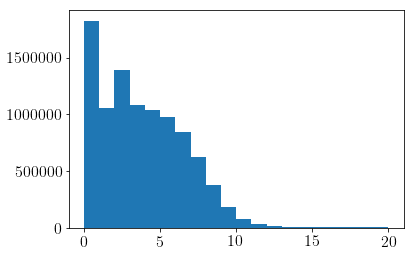

In [21]:
plt.hist(eli['ngood'][:,3],bins=20,range=(0,20))

(array([2.90000e+01, 2.95200e+03, 9.53400e+03, 1.59780e+04, 3.75580e+04,
        1.37919e+05, 2.05913e+05, 2.54743e+05, 3.05785e+05, 3.61419e+05,
        4.23822e+05, 4.89976e+05, 5.55733e+05, 6.25090e+05, 6.88282e+05,
        7.33655e+05, 7.75031e+05, 7.88769e+05, 3.20833e+05, 5.38900e+03]),
 array([16. , 16.4, 16.8, 17.2, 17.6, 18. , 18.4, 18.8, 19.2, 19.6, 20. ,
        20.4, 20.8, 21.2, 21.6, 22. , 22.4, 22.8, 23.2, 23.6, 24. ],
       dtype=float32),
 <a list of 20 Patch objects>)

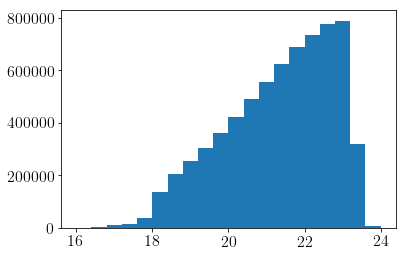

In [19]:
plt.hist(eli['mag_std_noabs'][:,3],bins=20,range=(16,24))

In [6]:
import lsst.afw.table as afwTable
cat = afwTable.BaseCatalog.readFits(fname)
print(cat.getMetadata())

BANDS = [ "N387", "g", "r", "i", "N816", "z", "N921", "y", "N1010" ]



In [20]:
allhsc=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_')